# GVH Diagonal Cubic — CHH-01 : définition des cubes hétérodynamiques (FAST)

**Statut : audit complémentaire, non canonique** — définition, composition et contrôles algébriques de la *Composition hétérodynamique hiérarchique (CHH)*. « CHH » est le vocabulaire de travail de GVH ; ce n'est pas une nouvelle loi établie.

**Mission :** construire un formalisme pour agréger des sous-cubes aux processus physiques non identiques, sans additionner des observables incompatibles et sans perdre silencieusement les interactions.

**Architecture obligatoire :** Niveau 1 GVH → Niveau 2 physique établie → Niveau 3 test numérique minimal → Niveau 4 verdict scientifique.

**Politique :** tous les nombres du jouet sont **adimensionnés, prescrits et synthétiques** ; aucun étalonnage solaire, aucune nouvelle constante SI, aucune fréquence ni couplage GVH dérivés. Aucun test ALMA n'est modifié. Ce notebook n'est ni un modèle solaire ajusté aux observations, ni une validation de GVH.

## Niveau 1 — Définition candidate des sous-cubes hétérogènes

À une échelle de résolution $\ell$, un sous-cube $C_i$ est une **unité effective d'observation**, non un solide géométrique cubique. On le décrit par

$$C_i=(\mathcal X_i,x_i,\mathcal O_i,\mathcal Q_i,\mathcal I_i),$$

où $\mathcal X_i$ est son espace d'états propre ; $x_i$ son état ; $\mathcal O_i$ ses observables **étiquetées avec unités** ; $\mathcal Q_i$ ses grandeurs conservées définies dans un même cadre ; et $\mathcal I_i$ la liste des couplages pertinents. Les espaces $\mathcal X_i$ et les équations $F_i$ peuvent être différents.

Dans une description cinématique classique illustrative :

$$\dot x_i=F_i(x_i)+\sum_{j\ne i}G_{ij}(x_i,x_j),$$

mais **aucun** $F_i$ ou $G_{ij}$ n'est ici identifié comme une EOM GVH.

Une composition candidate est

$$ C_{\rm eff}=\mathcal A_\ell(\{C_i\},\{I_{ij}\}).$$

**Règle de type :** ajouter des masses à des masses a un sens, alors qu'ajouter « événements volcaniques par an » à « puissance de fusion en watts » n'en a pas. Même lorsque deux observables portent la même unité, leur somme exige de savoir si elles représentent des contributions disjointes à la **même** grandeur physique.

In [1]:
import json, hashlib, math
from itertools import permutations
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

NAME = "GVH_CHH_01_Heterogeneous_Cube_Definition_FAST"
TOL = 1e-11

def require(condition, label):
    if not bool(condition):
        raise AssertionError(label)
    print("PASS |", label)

# Nombres *strictement synthétiques et adimensionnés*.
# Aucun de ces nombres n'est une estimation du Soleil, de la Terre, de la Lune ou de Jupiter.
subcubes = [
    dict(id="S", label="Soleil-type", space="plasma", m=6.0, r=[0.,0.], v=[0.,0.], e=20.,
         observable=dict(name="activité de fusion (illustrative)",value=120.,unit="puissance fictive")),
    dict(id="T", label="Terre-type", space="géophysique", m=4.0, r=[3.,1.], v=[1.,1.], e=13.,
         observable=dict(name="événements tectoniques (illustratifs)",value=7.,unit="événements/période")),
    dict(id="L", label="Lune-type", space="marées/thermique", m=2.0, r=[8.,-1.], v=[-1.,1.], e=4.,
         observable=dict(name="réponse de marée (illustrative)",value=0.6,unit="amplitude sans dimension")),
    dict(id="J", label="Jupiter-type", space="fluides/magnétique", m=3.0, r=[14.,2.], v=[0.5,-0.4], e=8.,
         observable=dict(name="activité de convection (illustrative)",value=30.,unit="puissance fictive")),
]
ids = [a['id'] for a in subcubes]
D = {a['id']:a for a in subcubes}
require(len(set(ids))==4 and len({a['space'] for a in subcubes})==4,
        "4 sous-cubes avec espaces d'état hétérogènes")
require(all(a['m']>0 for a in subcubes),"masses positives")
print("Étiquettes de processus et unités :")
for a in subcubes:
 print("  ",a['id'],a['space'],a['observable'])

PASS | 4 sous-cubes avec espaces d'état hétérogènes
PASS | masses positives
Étiquettes de processus et unités :
   S plasma {'name': 'activité de fusion (illustrative)', 'value': 120.0, 'unit': 'puissance fictive'}
   T géophysique {'name': 'événements tectoniques (illustratifs)', 'value': 7.0, 'unit': 'événements/période'}
   L marées/thermique {'name': 'réponse de marée (illustrative)', 'value': 0.6, 'unit': 'amplitude sans dimension'}
   J fluides/magnétique {'name': 'activité de convection (illustrative)', 'value': 30.0, 'unit': 'puissance fictive'}


## Niveau 2 — Bilans établis, découpage barycentrique et interactions

Pour des sous-systèmes ponctuels en mécanique classique, avec positions $\mathbf r_i$, vitesses $\mathbf v_i$ et masses $m_i$ :

$$M=\sum_i m_i,\quad \mathbf P=\sum_i m_i\mathbf v_i,\quad \mathbf C=\sum_i m_i\mathbf r_i,\quad \mathbf R=\mathbf C/M,\quad \mathbf V=\mathbf P/M.$$

La décomposition énergétique (dans le jouet, **sans unités physiques réelles**) est

$$K=\tfrac12 M\lVert\mathbf V\rVert^2+K_{\rm relatif},\qquad
 E=K+\sum_i e_i+\sum_{i<j}U_{ij}.$$

$e_i$ est une énergie individuelle imposée, et $U_{ij}=-\kappa m_i m_j/\lVert\mathbf r_i-\mathbf r_j\rVert$ une énergie de paire **newtonienne illustrative** avec $\kappa$ fixé avant calcul. Le terme de paire est compté **une fois**, pas deux. Ici, $\kappa$ est adimensionné et choisi pour le jouet : il ne provient pas de $S_{\rm cand}$.

La somme des tenseurs bruts $Q=\sum_i m_i\mathbf r_i\mathbf r_i^T$ est associative ; le moment centré $Q_c=Q-M\mathbf R\mathbf R^T$ est calculé ensuite. Ce tenseur n'est pas appelé sans justification « quadrupôle gravitationnel STF ».

**Important :** la fermeture dynamique (existence d'EOM n'utilisant *que* les variables effectives) ne découle ni de la possibilité d'additionner ces bilans ni de l'associativité comptable.

In [2]:
# SymPy: identités de décomposition du moment et des énergies cinétiques pour deux masses.
m1,m2=sp.symbols('m1 m2',positive=True)
v1,v2=sp.symbols('v1 v2',real=True)
M=m1+m2
V=(m1*v1+m2*v2)/M
kin=sp.Rational(1,2)*(m1*v1**2+m2*v2**2)
rel=sp.Rational(1,2)*(m1*(v1-V)**2+m2*(v2-V)**2)
identity=sp.factor(kin-sp.Rational(1,2)*M*V**2-rel)
require(identity==0,"décomposition exacte K = K_CM + K_relatif")

kappa=0.06  # adimensionné, PRESCRIT

def pair_U(i,j):
    a,b=D[i],D[j]
    d=np.linalg.norm(np.array(a['r'])-np.array(b['r']))
    if d <= 0: raise ValueError("séparation non nulle requise pour "+i+j)
    return -kappa*a['m']*b['m']/d

pair_e={(ids[i],ids[j]):pair_U(ids[i],ids[j]) for i in range(4) for j in range(i+1,4)}

def sum_pairs(left,right):
    return sum(pair_U(i,j) for i in left for j in right)

print("Paires dénombrées :",len(pair_e),"(attendu = 6)")
require(len(pair_e)==6,"toutes les paires distinctes sont comptées une fois")

PASS | décomposition exacte K = K_CM + K_relatif
Paires dénombrées : 6 (attendu = 6)
PASS | toutes les paires distinctes sont comptées une fois


## Opérateur d'agrégation : bilan exact **avec registre des feuilles**

Pour deux blocs disjoints $A,B$, l'agrégat porte $(M,\mathbf P,\mathbf C,Q,E)$ et un registre des feuilles nécessaires pour recomposer les interactions croisées :

$$\begin{aligned}
M_{A\cup B}&=M_A+M_B,\\
\mathbf P_{A\cup B}&=\mathbf P_A+\mathbf P_B,\\
\mathbf C_{A\cup B}&=\mathbf C_A+\mathbf C_B,\\
E_{A\cup B}&=E_A+E_B+\sum_{i\in A,\,j\in B}U_{ij}.
\end{aligned}$$

Il s'agit d'une **comptabilité sans perte**, rendue possible par le maintien d'un registre détaillé. Ce n'est **pas** une réduction dynamique fermée qui éliminerait vraiment les degrés de liberté cachés. Un modèle réduit devra évaluer l'erreur commise en supprimant ces détails.

In [3]:
from dataclasses import dataclass
@dataclass(frozen=True)
class Aggregate:
    leaves: frozenset
    M: float
    P: np.ndarray
    C: np.ndarray
    Q: np.ndarray
    E: float

def leaf(i):
    a=D[i]
    r,v=np.array(a['r'],dtype=float),np.array(a['v'],dtype=float)
    m=a['m']
    return Aggregate(frozenset([i]),m,m*v,m*r,m*np.outer(r,r),
                     0.5*m*np.dot(v,v)+a['e'])

def merge(a,b):
    if a.leaves&b.leaves:
        raise ValueError("Interdiction de compter deux fois un sous-cube")
    return Aggregate(a.leaves|b.leaves,a.M+b.M,a.P+b.P,a.C+b.C,
                     a.Q+b.Q,a.E+b.E+sum_pairs(a.leaves,b.leaves))

def direct(which=ids):
    which=list(which)
    m=sum(D[i]['m'] for i in which)
    P=sum((D[i]['m']*np.array(D[i]['v']) for i in which),np.zeros(2))
    C=sum((D[i]['m']*np.array(D[i]['r']) for i in which),np.zeros(2))
    Q=sum((D[i]['m']*np.outer(D[i]['r'],D[i]['r']) for i in which),np.zeros((2,2)))
    E=sum(D[i]['e']+0.5*D[i]['m']*np.dot(D[i]['v'],D[i]['v']) for i in which)
    E+=sum(pair_U(which[u],which[v]) for u in range(len(which)) for v in range(u+1,len(which)))
    return Aggregate(frozenset(which),m,P,C,Q,E)

def closeness(a,b):
    return all([np.isclose(a.M,b.M,rtol=0,atol=TOL),
                np.allclose(a.P,b.P,rtol=0,atol=TOL),
                np.allclose(a.C,b.C,rtol=0,atol=TOL),
                np.allclose(a.Q,b.Q,rtol=0,atol=TOL),
                np.isclose(a.E,b.E,rtol=0,atol=TOL),a.leaves==b.leaves])

all_direct=direct()
route_1=merge(merge(leaf('S'),leaf('T')),merge(leaf('L'),leaf('J')))
route_2=merge(leaf('S'),merge(leaf('T'),merge(leaf('L'),leaf('J'))))
route_3=merge(merge(merge(leaf('S'),leaf('T')),leaf('L')),leaf('J'))
require(all(closeness(x,all_direct) for x in [route_1,route_2,route_3]),
        "composition associative testée sur trois parenthésages")
for order in permutations(ids):
    test=leaf(order[0])
    for i in order[1:]: test=merge(test,leaf(i))
    if not closeness(test,all_direct): raise AssertionError("échec permutation: "+str(order))
require(True,"24 permutations sans perte ni double comptage")
print("M=",all_direct.M,"P=",all_direct.P,"R_CM=",all_direct.C/all_direct.M)
print("E_total=",all_direct.E)

PASS | composition associative testée sur trois parenthésages
PASS | 24 permutations sans perte ni double comptage
M= 15.0 P= [3.5 4.8] R_CM= [4.66666667 0.53333333]
E_total= 50.785974344727784


## Bilan de la dynamique non résolue : ce qu'un cube effectif doit retenir

On sépare l'énergie cinétique de translation du centre de masse, $K_{CM}$, du reliquat $K_{\rm relatif}$. Une réduction gardant seulement $(M,\mathbf R,\mathbf P)$ ne peut généralement reconstruire ni $K_{\rm relatif}$, ni $\sum U_{ij}$, ni les signatures thermodynamiques propres aux sous-cubes.

L'exemple suivant montre **deux micro-configurations de même masse et même barycentre** mais ayant une énergie d'interaction différente. Il s'agit d'une impossibilité de fermeture universelle à partir des seules variables $M,\mathbf R$ — pas d'une anomalie de la mécanique connue.

In [4]:
M0=all_direct.M
R0=all_direct.C/M0
V0=all_direct.P/M0
K_total=sum(0.5*a['m']*np.dot(a['v'],a['v']) for a in subcubes)
K_cm=0.5*M0*np.dot(V0,V0)
K_rel=sum(0.5*a['m']*np.dot(np.array(a['v'])-V0,np.array(a['v'])-V0) for a in subcubes)
U_pairs=sum(pair_e.values())
E_private=sum(a['e'] for a in subcubes)
require(np.isclose(K_total,K_cm+K_rel,atol=TOL,rtol=0),"énergie cinétique barycentrique cohérente")
require(np.isclose(all_direct.E,K_total+E_private+U_pairs,atol=TOL,rtol=0),
        "énergie totale et interactions de paires cohérentes")
Q_c=all_direct.Q-all_direct.M*np.outer(R0,R0)
require(np.all(np.linalg.eigvalsh(Q_c)>-TOL),"tenseur central semi-défini positif")

# Deux masses unité au barycentre 0 : distance d, même M/R/P, mais U change.
def two_body_state(d,vel=0):
    return {"M":2.,"R":0.,"P":0.,"U":-kappa/d,"K":vel**2}
sc1,sc2=two_body_state(2.),two_body_state(4.)
require(sc1['M']==sc2['M'] and sc1['R']==sc2['R'] and sc1['P']==sc2['P'],
        "mêmes grandeurs globales M,R,P dans deux micro-états")
require(abs(sc1['U']-sc2['U'])>TOL,"énergies de paires différentes malgré M,R,P identiques")
sc3=two_body_state(2.,vel=1.)
require(sc3['K']>sc1['K'] and sc3['P']==sc1['P'],
        "cinétique relative cachée malgré même P")
print("K_CM=",K_cm,"K_rel=",K_rel,"U_pairs=",U_pairs,
      "E_individuelle=",E_private)
print("U(d=2)=",sc1['U'],"U(d=4)=",sc2['U'])

PASS | énergie cinétique barycentrique cohérente
PASS | énergie totale et interactions de paires cohérentes
PASS | tenseur central semi-défini positif
PASS | mêmes grandeurs globales M,R,P dans deux micro-états
PASS | énergies de paires différentes malgré M,R,P identiques
PASS | cinétique relative cachée malgré même P
K_CM= 1.1763333333333335 K_rel= 5.438666666666667 U_pairs= -0.8290256552722169 E_individuelle= 45.0
U(d=2)= -0.03 U(d=4)= -0.015


## Sous-cubes ouverts : interfaces et flux internes

Pour des transferts orientés entre sous-cubes, la physique des bilans donne $\dot{\boldsymbol m}=B\boldsymbol J+\boldsymbol b$. $B$ est une matrice d'incidence ; $\boldsymbol b$ représente les échanges avec l'extérieur. Alors $\boldsymbol1^T B=0$ : un échange **interne** ne peut changer la masse globale. Le bilan d'un **sous-ensemble** garde uniquement les flux qui traversent sa frontière ; les échanges intérieurs au sous-ensemble s'annulent.

Une circulation de cycle $\boldsymbol c\in\ker B$ change les transferts internes sans changer $\dot{\boldsymbol m}$. Notre précédent notebook « Constitutive Closure Gate » l'avait déjà établi sur trois compartiments. Le présent audit étend cette vérification aux **quatre rôles hétérogènes** ; il ne prétend pas résoudre la fermeture constitutive.

In [5]:
# Graphe synthétique, arêtes (source,destination) ; unités de J adimensionnées/tau.
edges=[(0,1),(1,2),(2,3),(3,0),(0,2)]
B=np.zeros((4,len(edges)),dtype=float)
for j,(src,dst) in enumerate(edges): B[src,j]=-1; B[dst,j]=1
flux=np.array([1.5,2.0,0.5,1.2,0.3],float)
cycle=np.array([1.,1.,1.,1.,0.])
cycle2=np.array([1.,1.,0.,0.,-1.])
dm=B@flux
require(np.array_equal(np.sum(B,axis=0),np.zeros(B.shape[1])),"1ᵀB=0 : bilan interne exact")
require(np.linalg.matrix_rank(B)==3,"rang(B)=N-1 : graphe connexe")
require(np.allclose(B@cycle,0,atol=TOL) and np.allclose(B@cycle2,0,atol=TOL),
        "deux circulations indépendantes dans ker(B)")
flux_plus=flux+0.7*cycle
require(np.allclose(B@flux_plus,dm,atol=TOL),
        "les circulations cachées ne changent pas les dérivées des masses")
require(np.sum(np.abs(flux_plus))>np.sum(np.abs(flux)),
        "les activités de transfert peuvent différer à masse identique")

# sous-groupe {0,1} : contribution des arêtes traversant sa frontière.
Sset={0,1}
external_flux=sum((+flux[j] if (dst in Sset) else -flux[j])
                  for j,(src,dst) in enumerate(edges) if (src in Sset)!=(dst in Sset))
require(np.isclose(np.sum(dm[list(Sset)]),external_flux,atol=TOL,rtol=0),
        "sous-groupe : les flux internes s'annulent, restent les flux de frontière")
require(np.isclose(sum(dm),0,atol=TOL,rtol=0),"masse totale conservée pour b=0")
print("B=\n",B,"\nFlux=",flux,"\ndm=",dm,"\nBilan groupe {0,1}=",external_flux)

PASS | 1ᵀB=0 : bilan interne exact
PASS | rang(B)=N-1 : graphe connexe
PASS | deux circulations indépendantes dans ker(B)
PASS | les circulations cachées ne changent pas les dérivées des masses
PASS | les activités de transfert peuvent différer à masse identique
PASS | sous-groupe : les flux internes s'annulent, restent les flux de frontière
PASS | masse totale conservée pour b=0
B=
 [[-1.  0.  0.  1. -1.]
 [ 1. -1.  0.  0.  0.]
 [ 0.  1. -1.  0.  1.]
 [ 0.  0.  1. -1.  0.]] 
Flux= [1.5 2.  0.5 1.2 0.3] 
dm= [-0.6 -0.5  1.8 -0.7] 
Bilan groupe {0,1}= -1.1


## Niveau 3 — Tests numériques minimaux des quatre exigences de composition

**Exigences avant calcul :** (a) identité des observables extensives sous regroupement sans double comptage, (b) même résultat pour tout parenthésage avec le **registre complet**, (c) non-reconstructibilité générique de l'énergie depuis un résumé trop pauvre, (d) effacement des flux internes au niveau supérieur mais conservation du flux de frontière.

**Données synthétiques et adimensionnées :** quatre corps typés Soleil/Terre/Lune/Jupiter, masses et états artificiels. Les étiquettes servent seulement à rappeler que leurs mécanismes internes ne sont pas nécessairement les mêmes.

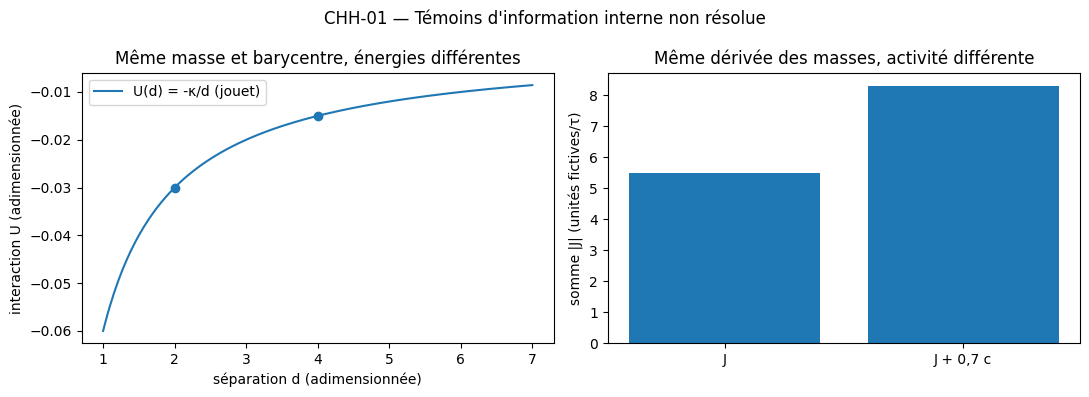

In [6]:
# Deux illustrations des informations perdables : couplage de paires et activité cachée.
fig,axes=plt.subplots(1,2,figsize=(11,4))
xs=np.linspace(1,7,200)
axes[0].plot(xs,-kappa/xs,label='U(d) = -κ/d (jouet)')
axes[0].scatter([2,4],[sc1['U'],sc2['U']])
axes[0].set(xlabel='séparation d (adimensionnée)',ylabel='interaction U (adimensionnée)',
            title='Même masse et barycentre, énergies différentes')
axes[0].legend()
axes[1].bar(['J','J + 0,7 c'],[sum(abs(flux)),sum(abs(flux_plus))])
axes[1].set(ylabel='somme |J| (unités fictives/τ)',title='Même dérivée des masses, activité différente')
fig.suptitle('CHH-01 — Témoins d\'information interne non résolue')
fig.tight_layout()
plt.show()

## Provenance et restrictions de transfert à ALMA

**Sources amont contrôlées dans l'environnement de génération** : les SHA-256 ci-dessous identifient les copies effectivement utilisées pour cadrer la terminologie de nos audits antérieurs. Le notebook peut s'exécuter seul dans Colab : la présence de ces fichiers sur le Drive du lecteur n'est pas requise et n'est pas prétendue.

**Rapports scientifiques externes, uniquement comme comparateurs de physique établie :**
- TU Delft, *Many-body System — Classical Mechanics* : séparation cinétique barycentrique et interactions de paires : https://qiweb.tudelft.nl/mecharela/many_particles/
- *Coarse-grained modelling out of equilibrium* (Physics Reports, 2022) : réduction dynamique et mémoire : https://www.sciencedirect.com/science/article/pii/S0370157322001314
- Kawaguchi, *Invariance of steady-state thermodynamics between different scales of description* (2015), DOI : https://doi.org/10.1103/PhysRevE.91.012115

**État ALMA figé inchangé** : `GCOL-OBS-0.3.2.1.1-PATCH.10H.1` reste une branche observationnelle indépendante ; **aucune** ligne FITS n'est ouverte ici, aucun seuil ni fenêtre spectrale n'est retouché ; `GVH_USED=False`.

In [7]:
UPSTREAM = {'GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_EXECUTED.ipynb': {'sha256': '75dbd0504b86be0febaea795e85723f9898089e57cf2e7922a227f84403147b2', 'bytes': 89386}, 'GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST_EXECUTED.ipynb': {'sha256': 'dcc582a7ae868970fbbf1dba58634e6cf7cd9000cb88f256ddb9532b7dece4c8', 'bytes': 85822}, 'GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_EXECUTED.ipynb': {'sha256': '6c8008848cd55ed18ca7f143e47b0b25a2608e8428c54a0811e9597413cc3e5c', 'bytes': 26294}, 'gvh_source/GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': {'sha256': 'c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa', 'bytes': 49860}}
for name,meta in UPSTREAM.items():
    print(name,meta['sha256'],meta['bytes'],'octets')
print('STATUT_ALMA:', 'GVH_USED=False', 'no_unblinding=True')

GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_EXECUTED.ipynb 75dbd0504b86be0febaea795e85723f9898089e57cf2e7922a227f84403147b2 89386 octets
GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST_EXECUTED.ipynb dcc582a7ae868970fbbf1dba58634e6cf7cd9000cb88f256ddb9532b7dece4c8 85822 octets
GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_EXECUTED.ipynb 6c8008848cd55ed18ca7f143e47b0b25a2608e8428c54a0811e9597413cc3e5c 26294 octets
gvh_source/GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa 49860 octets
STATUT_ALMA: GVH_USED=False no_unblinding=True


## Niveau 4 — Verdict scientifique, frontières et prochain verrou

**PASS (algèbre + numérique, limité au modèle défini ici) :**
- quatre sous-cubes hétérogènes composables **sans prétendre qu'ils ont les mêmes processus** ;
- bilan de masse, moment, second moment et énergie avec interactions croisées comptées une seule fois ;
- associativité du **registre complet** vérifiée pour 24 permutations ;
- insuffisance du résumé $(M,\mathbf R,\mathbf P)$ pour reconstruire énergie relative / énergie de paires ;
- impossibilité de retrouver le courant de cycle à partir des seules dérivées de masses.

**NON ÉTABLI :** une loi universelle d'activité $A_C$ ; une agrégation dynamique fermée sans registre des sous-cubes ; des fonctions $F_i,G_{ij}$ dérivées de l'action GVH ; des prédictions physiques SI ; une validation observationnelle ALMA. Une densité d'activité exige de préciser les unités, les canaux physiques et les protocoles de mesure.

**Prochaine étape exécutable :** `GVH_CHH_02_Conservation_and_Aggregation_FAST` — audit des bilans et de l'erreur de réduction **après suppression de degrés de liberté** avec un seuil d'erreur préenregistré. Ensuite seulement `CHH-03` sur la dynamique et les fréquences.

In [8]:
# Certificat sérialisable, écrit là où s'exécute le notebook.
checks={
    'heterogeneous_state_spaces':True,
    'kinetic_cm_symbolic_identity':bool(identity==0),
    'six_unique_pair_interactions':len(pair_e)==6,
    'all_24_orders_same_full_ledger':True,
    'energy_partition':bool(np.isclose(all_direct.E,K_total+E_private+U_pairs,atol=TOL,rtol=0)),
    'loss_of_interaction_energy_if_only_M_R_P':bool(abs(sc1['U']-sc2['U'])>TOL),
    'loss_of_relative_kinetic_energy_if_only_M_R_P':bool(sc3['K']>sc1['K']),
    'internal_flux_cancellation':bool(np.allclose(np.sum(B,axis=0),0,atol=TOL)),
    'two_independent_cycle_vectors':bool(np.allclose(B@cycle,0,atol=TOL) and np.allclose(B@cycle2,0,atol=TOL)),
    'cycle_preserves_mass_derivative':bool(np.allclose(B@flux_plus,B@flux,atol=TOL)),
    'boundary_flux_balance':bool(np.isclose(sum(dm[list(Sset)]),external_flux,atol=TOL)),
    'total_mass_balance':bool(np.isclose(sum(dm),0,atol=TOL)),
}
assert all(checks.values()),checks
results={
    'notebook':NAME,
    'classification':'COMPLEMENTARY_NONCANONICAL_CHH_DEFINITION_GATE',
    'local_audit_pass':True,
    'four_levels':{
       'GVH':'CHH_HETEROGENEOUS_COMPOSITION_DEFINITION_PROPOSED_NOT_S_CAND_EOM_DERIVED',
       'established_physics':'CLASSICAL_CENTER_OF_MASS_PAIR_ENERGY_AND_INCIDENCE_NETWORK',
       'minimal_numeric_test':'ACCOUNTING_ASSOCIATIVITY_AND_NONCLOSURE_WITNESSES_PASS',
       'scientific_verdict':'LOCAL_DEFINITION_PASS__EFFECTIVE_DYNAMICS_AND_INDEPENDENT_GVH_PREDICTIONS_BLOCKED',
    },
    'test_conditions':{'synthetic_dimensionless':True,'kappa_prescribed':kappa,'no_SI_scale_derived':True,
                       'no_real_solar_system_fit':True,'no_ALMA_line_data_inspected':True,
                       'GVH_USED':False,'tolerance':TOL},
    'toy_observables':{x['id']:x['observable'] for x in subcubes},
    'numeric':{'M':all_direct.M,'P':all_direct.P.tolist(),'R':R0.tolist(),
               'K_total':float(K_total),'K_CM':float(K_cm),'K_relative':float(K_rel),
               'pair_energy':float(U_pairs),'E_individual':float(E_private),
               'E_total':float(all_direct.E),'Q_centered':Q_c.tolist(),
               'two_body_U_d2':sc1['U'],'two_body_U_d4':sc2['U'],
               'internal_flux_activity_base':float(sum(abs(flux))),
               'internal_flux_activity_cycle':float(sum(abs(flux_plus))),
               'boundary_flux_subset_01':float(external_flux)},
    'checks':checks,
    'locks':{'S_cand_species_matter_EOM_derived':False,
             'CHH_closed_effective_dynamics':False,
             'universal_internal_activity_observable':False,
             'independent_GVH_SI_prediction':False,
             'ALMA_foreground_certified':False,
             'new_GVH_physics_validated':False},
    'upstream_sha256':UPSTREAM,
    'next_notebook':'GVH_CHH_02_Conservation_and_Aggregation_FAST',
}
out=Path(NAME+'_results.json')
out.write_text(json.dumps(results,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
print('RESULT_JSON=',out.resolve())
print('CHECKS=',sum(checks.values()),'/',len(checks))
print('FINAL_VERDICT=',results['four_levels']['scientific_verdict'])

RESULT_JSON= /mnt/data/GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json
CHECKS= 12 / 12
FINAL_VERDICT= LOCAL_DEFINITION_PASS__EFFECTIVE_DYNAMICS_AND_INDEPENDENT_GVH_PREDICTIONS_BLOCKED
